In [1]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *

# A Python Implementation of the Critical Electric Field

Based on https://github.com/hesslow/Eceff/

In [3]:
### Functions ####

def calcDelta(Eceff,nuD0,nuS1,tauRadInv,phib1,phib2,pc0):
    return (nuD0/nuS1**2)*(nuD0*tauRadInv/Eceff+phib1+phib2*np.log(pc0))

def calcEceff(delta,nuS0,nuS1,nuD1,nuD0,pc0):
    return nuS0 + nuS1*( (1+nuD1/nuD0)*np.log(pc0) + np.sqrt(2*delta+1))

def getEc_eff(Z,Z0,nj,T,B):
    
    # Returns the effective critical electric field and Ectot with Ne impurities in V/m
    # INPUTS:
    #       Z   : atomic number of each ion species
    #       Z0  : net charge of plasma for each ion species
    #       nj  : density of each ion species [m^(-3)]
    #       Z, Z0 and nj must be arrays of length nSpecies
    #       T   : temperature [eV]  (for calculation of the Coulomb logarithm)
    #       B   : magnetic field [T]
   
    # Constants for Ne
    ln_aBar_Ne = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
    ln_I_Ne = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    ntot = np.sum(Z * nj) # Bound + Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Zfulleff = np.sum(Z**2 * nj)/ne_free 
    lnLStar = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # Coul. Log
    Ne = Z - Z0 # No. of bound electrons

    ## calculate the constants nuD0, nuD1, nuS0, nuS1
    nuD0 = (1 + Zeff) - 2/3 * np.sum(Ne**2 * nj)/ne_free /lnLStar
    nuD1 = Zfulleff/lnLStar
    nuS0 = 1
    nuS1 = (1 + 3 * np.sum(Ne * nj)/ne_free)/(2*lnLStar)
    for i in range(1,Z.shape[0]):
        nuD0 = nuD0 + (Z[i]**2 - Z0[i]**2) * ln_aBar_Ne[Z0[i]] * (nj[i]/ne_free) / lnLStar
        nuS0 = nuS0 + Ne[i] * (-ln_I_Ne[Z0[i]]-1) * (nj[i]/ne_free) / lnLStar

    #### Radiation Terms ####

    # synchrotron radiation term
    tauRadInv =  B**2/(ne_free/1e20)/(15.44*lnLStar);

    # bremsstrahlung term
    ALPHA = 1/137.036;
    bremsprefactor = ALPHA * Zfulleff/lnLStar;
    phib1 = bremsprefactor*0.35;
    phib2 = bremsprefactor*0.20;

    pc0 = nuD0/(2*nuS1);

    Ectot = ntot/ne_free # in units of E_c
    Eceff0 = Ectot
    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)
    delta1 = calcDelta(calcEceff(delta0,
                                nuS0,nuS1,nuD1,nuD0,pc0),
                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)

    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot
    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2);
    
    return Ectot * EceffOverEctot, Ectot


In [4]:
## Example Usage ##

# Inputs
Z = np.array([1,10]); # Max. Ionization, the first entry is for fully ionized deuterium, second for partially ionized Ne
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;
B = 0; 


Ec_eff = getEc_eff(Z,Z0,nj,T,B) # [V/m] Call the function

print('Eceff [V/m] = %1.3f\n'%(Ec_eff[0]))
print('Ectot [V/m] = %1.3f\n'%(Ec_eff[1]))


Eceff [V/m] = 0.876

Ectot [V/m] = 0.864



(1e+19, 1e+21)

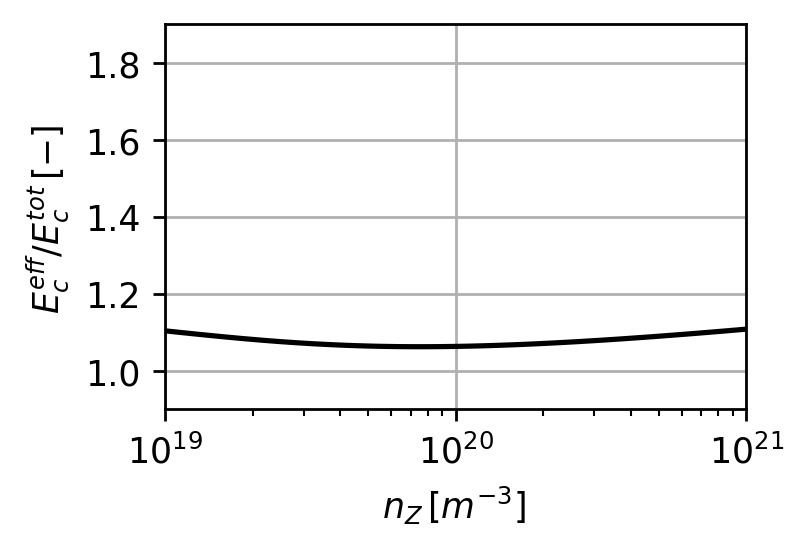

In [5]:
# Calculating Eeff with Ne impurities - vary nz

# Inputs
nz = np.logspace(19,21,100)
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,2]); # Ionization Level
T = 10;
B = 0; 

Ec_eff = np.zeros_like(nz)
for ii in range(nz.shape[0]):
    nj = np.array([1e20,nz[ii]]); # Density
    out = getEc_eff(Z,Z0,nj,T,B) # [Ec_eff, Ec_tot] in [V/m]
    Ec_eff[ii] = out[0]/out[1] # Ec_eff / Ec_tot

    
# Plot #
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=250)
plt.plot(nz,Ec_eff,'-k')
plt.xscale('log')
plt.ylim([0.9,1.9])
plt.xlabel('$n_Z \, [m^{-3}]$ ')
plt.ylabel('$E_c^{eff}/E_c^{tot} \, [-]$ ')
plt.grid()
plt.xlim([1e19,1e21])


### Recreate the following figures and comapre the implementation

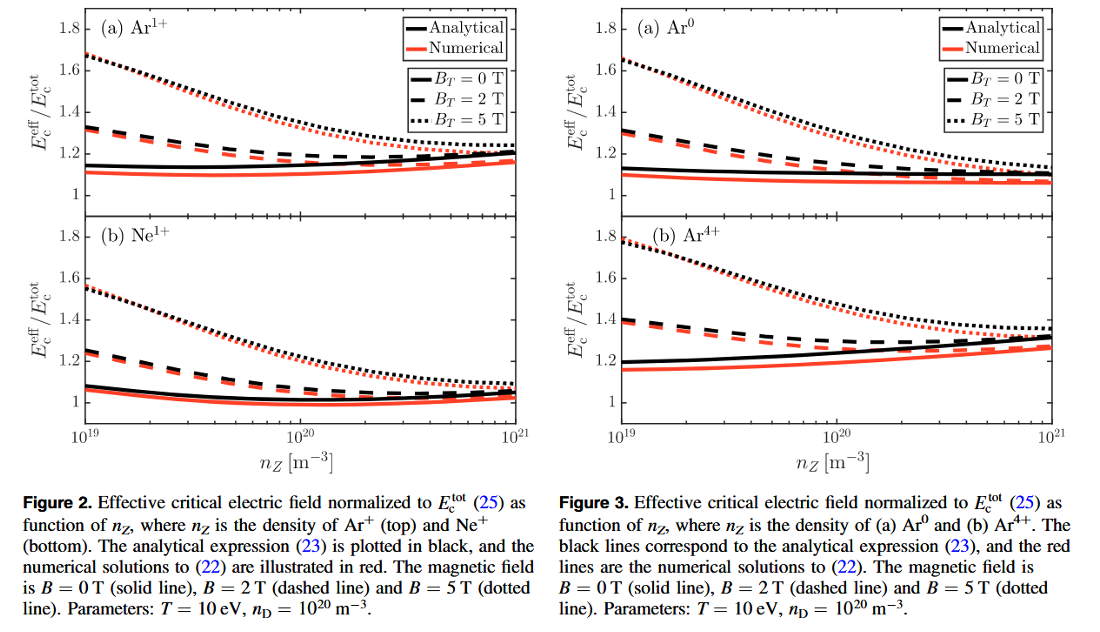